# 제13장 추가 실습 노트북

장 폴더에서 위에서 아래로 실행하세요. 프로그램 원본과 동일한 코드를 `%run`으로 실행합니다. 데이터 출처·가정·학습 범위는 각 절의 README를 함께 확인하세요. CSV는 내려받은 고정 입력이며 외부 API·GPU가 필요하지 않습니다.

In [1]:
import sys
from pathlib import Path
print("Python:", sys.version.split()[0])
print("Working folder:", Path.cwd())

Python: 3.12.14
Working folder: /workspace/scratch/52b332c0a516/textbook_repo/textbook_extensions/20261016/ch13


## 13.11 PSI·KS와 분포 이동 모니터링

분포 모양과 PSI 기여 구간, KS 통계량을 함께 확인한다.

빈 경계는 기준 자료의 분위수에서만 정했다. 양끝은 무한대로 열어 현재 값이 기준 범위를 벗어나도 누락되지 않게 한다.

주의: PSI의 고정 경보 기준은 업종·표본·특성마다 검증해야 한다. 입력 드리프트를 성능 하락이나 개념 드리프트와 동일시하지 않는다.

In [2]:
%run sec_11_drift_monitor.py

{
  "PSI": 0.3512911234541295,
  "KS_statistic": 0.258,
  "KS_pvalue": 4.977431397171044e-15,
  "reference_n": 500,
  "current_n": 500
}


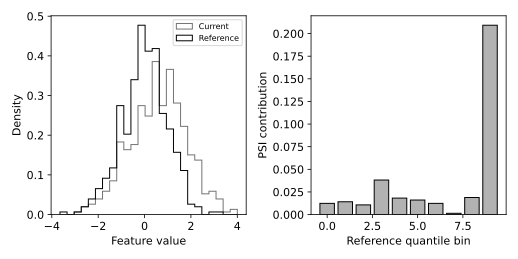

In [3]:
from IPython.display import SVG, display
display(SVG(filename="results/drift_monitor.svg"))

### 확인 과제

현재 열에 기준 열을 복사한 비교 시나리오를 만들어 PSI가 0에 가까워지는지 확인한다.

## 13.12 모델 저장·복원과 배치 추론 입력 검증

전처리와 회귀 모델을 함께 저장하고 복원 전후 예측과 입력 거부 동작을 확인한다.

대각선에 점이 놓이면 저장·복원 전후 출력이 같다. 실제 정답과 예측이 같다는 그림은 아니다.

주의: 웹 서버를 배포한 예제가 아니다. 신뢰할 수 없는 joblib 파일은 열지 않으며 운영 버전·권한·동시 요청은 별도 구현이 필요하다.

In [4]:
%run sec_12_model_roundtrip.py

{
  "test_n": 108,
  "max_abs_diff": 0.0,
  "test_RMSE": 0.19421003354419544,
  "missing_field_rejected": "Missing fields: ['x1']"
}


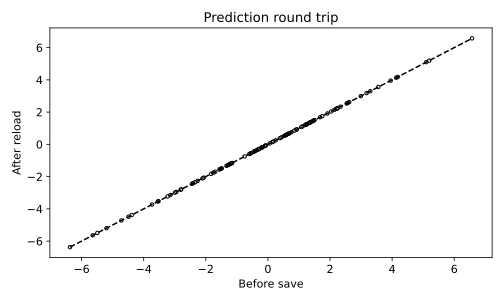

In [5]:
from IPython.display import SVG, display
display(SVG(filename="results/model_roundtrip.svg"))

### 확인 과제

열 순서를 뒤집어도 features로 재정렬되는지 확인하고 NaN 입력의 거부를 추가 점검한다.